In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
data = pd.read_csv("../other/Mental_Health_and_Social_Media_Balance_Dataset.csv")
df = pd.DataFrame(data)
df.head()

,User_ID,Age,Gender,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Social_Media_Platform,Happiness_Index(1-10)
0,U001,44,Male,3.1,7.0,6.0,2.0,5.0,Facebook,10.0
1,U002,30,Other,5.1,7.0,8.0,5.0,3.0,LinkedIn,10.0
2,U003,23,Other,7.4,6.0,7.0,1.0,3.0,YouTube,6.0
3,U004,36,Female,5.7,7.0,8.0,1.0,1.0,TikTok,8.0
4,U005,34,Female,7.0,4.0,7.0,5.0,1.0,X (Twitter),8.0


In [5]:
df = df.drop(['User_ID'], axis=1)
df.tail()

,Age,Gender,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Social_Media_Platform,Happiness_Index(1-10)
495,23,Male,6.9,5.0,7.0,4.0,2.0,X (Twitter),10.0
496,43,Female,5.6,7.0,6.0,5.0,2.0,Facebook,9.0
497,41,Male,7.7,5.0,7.0,2.0,2.0,LinkedIn,8.0
498,23,Male,4.2,9.0,7.0,0.0,2.0,Facebook,9.0
499,43,Female,5.9,5.0,8.0,3.0,3.0,X (Twitter),7.0


In [7]:
df.describe()

,Age,Daily_Screen_Time(hrs),Sleep_Quality(1-10),Stress_Level(1-10),Days_Without_Social_Media,Exercise_Frequency(week),Happiness_Index(1-10)
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,32.988000,5.530000,6.304000,6.618000,3.134000,2.448000,8.376000
std,9.960637,1.734877,1.529792,1.542996,1.858751,1.428067,1.524228
min,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,4.000000
25%,24.000000,4.300000,5.000000,6.000000,2.000000,1.000000,7.000000
50%,34.000000,5.600000,6.000000,7.000000,3.000000,2.000000,9.000000
75%,41.000000,6.700000,7.000000,8.000000,5.000000,3.000000,10.000000
max,49.000000,10.800000,10.000000,10.000000,9.000000,7.000000,10.000000


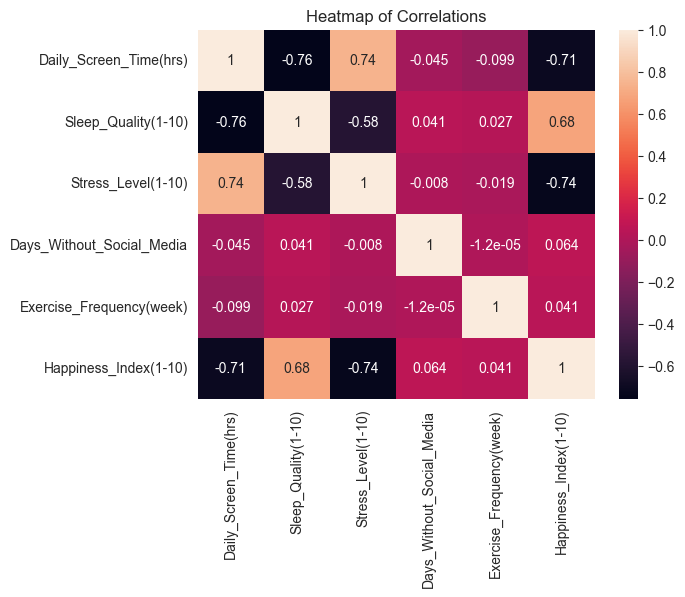

In [6]:
data_corr = df.drop(['Age'], axis=1)
correlation_matrix = data_corr.corr(numeric_only=True)
sns.heatmap(correlation_matrix, annot=True)

plt.title('Heatmap of Correlations')
plt.show()

In [12]:
print("\n-----CORRELATION (top pairs)-----")

corr_unstack = correlation_matrix.unstack().reset_index()
corr_unstack.columns = ['var1', 'var2', 'value']
corr_unstack = corr_unstack[corr_unstack['var1'] != corr_unstack['var2']]
corr_unstack['abs_value'] = corr_unstack['value'].abs()
corr_unstack = corr_unstack.sort_values('abs_value', ascending=False).drop_duplicates(subset=['value'])
display(corr_unstack.head(12))


-----CORRELATION (top pairs)-----


,var1,var2,value,abs_value
1,Daily_Screen_Time(hrs),Sleep_Quality(1-10),-0.758910,0.758910
2,Daily_Screen_Time(hrs),Stress_Level(1-10),0.739891,0.739891
32,Happiness_Index(1-10),Stress_Level(1-10),-0.737213,0.737213
5,Daily_Screen_Time(hrs),Happiness_Index(1-10),-0.705206,0.705206
31,Happiness_Index(1-10),Sleep_Quality(1-10),0.678829,0.678829
13,Stress_Level(1-10),Sleep_Quality(1-10),-0.584899,0.584899
4,Daily_Screen_Time(hrs),Exercise_Frequency(week),-0.099023,0.099023
23,Days_Without_Social_Media,Happiness_Index(1-10),0.063525,0.063525
3,Daily_Screen_Time(hrs),Days_Without_Social_Media,-0.045310,0.045310
29,Exercise_Frequency(week),Happiness_Index(1-10),0.041224,0.041224


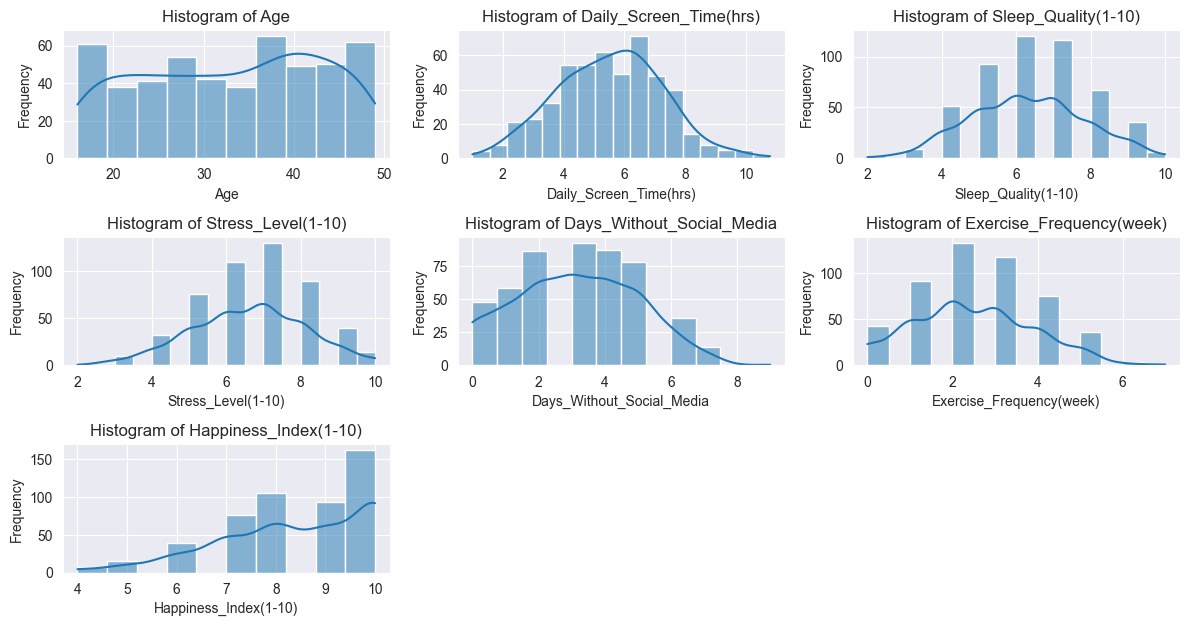

In [11]:
numeric_df = df.drop(['Gender','Social_Media_Platform'],axis=1)
plt.figure(figsize= (12,8))

for i, feature in enumerate(numeric_df.columns):
    plt.subplot(4,3,i+1)
    sns.histplot(numeric_df[feature], kde= True)
    plt.title(f'Histogram of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()